Mean Covariance Learning, Unit 2, Homework 1

MLFP - (Maximum Likelihood with Flexible Probabilities)
ML - Means choosing the parameters that make the data I actually observed most probable.
FP - Means the days dont count equally.

Maximum likelihood estimation: t MLFP ellipsoid

Reading material: before addressing this exercise - study the Maximum likelihood.

Code reference: Become familiar with script s_mlfp_ellipsoid_convergence which illustrates the maximum likelihood estimation of the mean and covariance.

Consider a bivariate i.i,d process Et = (E1,t, E2,t,....) which is a Student t distribution
distributed Et ~ t(Mu, sigma_2, v), with the following parameters

Mu = (0.49, -0.17),
sigma_2 = ((0.25, 0.3),(0.3, 4))
v = 3.

This whole notebook is one controlled experiment.
Where I invent a distribution, hide it from myself, then try to recover it from data
and then check how well I did.

Each Task is 1 step in the experiment, and each carries its own lesson.

In [15]:
from numpy import arange, array, degrees, exp, log, sqrt, sum
from numpy.linalg import eig, norm
from math import atan
from scipy.stats import multivariate_t
from matplotlib.patches import Ellipse
from matplotlib.pyplot import gca, legend
from seaborn import scatterplot
from arpym.fit_locdisp_mlfp import fit_locdisp_mlfp

Task 1

Generate a set of t^ = 1,000 observations {Et} t, t=1 for the process Et.

Simulate from a known distribution.

Draw 1,000 days of 2 variable data from a Student t distribution with v = 3.

Simulating gives the experiment the data for the question and the answer for the question.

Student t is more like "Real daily returns" than a normal distribution is.

Rule of thumb:

Mu and sigma2 are the settings of the model.

Mean and Covariance are properties of the data it produces.


In [16]:
#################  inputs  #################
# Location 'Mu' - (Center point, Not Mean)
mu = array([0.49, -0.17])

# Dispersion - the shape, size, tilt of the distribution
sigma2 = array([[0.25, 0.3], [0.3, 4]])

# degrees of freedom
nu = 3

# number of daily observations
t_bar = 1000
############################################

# scenarios
# using scipy's multivariate_t sampler
# loc=mu : is the location Mu, the centre of the cloud of points
# shape=sigma2 is the dispersion sigma squared,
# df=nu : degrees of freedom v = 3, giving fat tales and loads of outliers
# size=t_bar : 1000 (how many draws it takes)
# rvs : random variates/samples function
# random_state=42 : allows for reproducibility
eps = multivariate_t.rvs(loc=mu, shape=sigma2, df=nu, size=t_bar, random_state=42)

# verification
print(eps.shape)
print()
print(eps[:5])

(1000, 2)

[[ 0.72336298 -0.04696906]
 [ 1.16140613 -0.63336312]
 [ 1.43091407  2.70975687]
 [ 0.26459638 -4.57963552]
 [ 0.67847599  0.76966978]]


Task 2

Give each day a probability that decays with age, halving every 500 days.

The learning is that not all history is equally relevant, flexible probabilities encode that judgement.

Compute exponential decay probabilities {pt|THL}t^,t=1 with target t* = t^
and half life parameter THL = 500 days

The idea is to give recent days more weight than old ones, with the weight halving every T_HL = 500 days

as I go back in time from the target day t* = 1000

In [14]:
#################  input  #################
# half life parameter
tau_hl = 500
############################################

# Exponential Decay Weights
# arange(1, t_bar + 1) : gives the day numbers 1,2,...,1000,
# +1 is added as arange stops just before the end position
# t_bar - arange(...) gives each days distance back from target, 999, 998, 997,...,0
# Day 1000 is 0 days back
# -log(2) / tau_hl * distance makes the exponent more negative the older the day is
# exp(...) : turns the exponent into a weight, Day 1000 gets 1, day 500 = 0.5, day 1 gets 0.25
w = exp(-log(2) / tau_hl * (t_bar - arange(1, t_bar + 1)))

# Exponential Decay Probabilities (rescaled weights)
# the raw weights add up to a large number and not 1.
# Dividing each by the total makes them valid probabilities
p = w / sum(w)

# Verification
# The ratios between days don't change, so day 1000 still counts twice as much as day 500
# The only difference is that the whole set now sums to 1

# should be 1.0
print('The whole set sums to : ', p.sum())
print()
# last day vs day 500 - should be 2.0
print('The last day vs the day 500 should be : ', p[-1] / p[499])
print()
# effective number of scenarios -> about 866
print('The effective number of scenarios is : ', 1 / sum(p**2))


The whole set sums to :  1.0

The last day vs the day 500 should be :  2.0

The effective number of scenarios is :  865.61716316281


Task 3

MLFP estimation (the core lesson)

The learning is that
The estimator must match the data.
MLFP only works here because i told it the right v.
In a real data set 'v' is itself a modelling choice.
Two weightings stack together time weights (p) outlier weights (w)  (p * w).
This whole process has to iterate, start with a guess and refine it until
estimate of ellipse stops moving.


Compute the maximum likelihood with flexible probabilities (MLFP) estimates of location and
dispersion (Mu^ MLFP Et, sigma^2 MLFP E) Stemming from the observations {Et} t^, t=1 and
probabilities {pt|THL} t^, t=1 via the specific iterative routine.

This is where the actual estimation happens.

In [8]:
#################  inputs  #################
# MLFP routine convergence threshold
gamma = 0.00001
############################################

# MLFP estimates of location and dispersion
# eps is our data from task 1
# p is the array of time-decay probabilities array from Task 2
# nu is the degrees of freedom, telling to assume v = 3
# gamma is the convergence tolerance
# returns mu and sigma2
# help(fit_locdisp_mlfp)
mu_mlfp, sigma2_mlfp = fit_locdisp_mlfp(eps, p=p, nu=nu, threshold=gamma)

# verification
m_hfp = p @ eps
s2_hfp = ((eps - m_hfp).T * p) @ (eps - m_hfp)

print('true sigma2:\n', sigma2)
print()
print('HFP covariance:\n', s2_hfp.round(3))
print()
print('MLFP dispersion:\n', sigma2_mlfp.round(3))
print()
print('MLFP location:', mu_mlfp.round(3))


true sigma2:
 [[0.25 0.3 ]
 [0.3  4.  ]]

HFP covariance:
 [[ 0.717  1.17 ]
 [ 1.17  13.279]]

MLFP dispersion:
 [[0.253 0.284]
 [0.284 3.568]]

MLFP loction: [ 0.48  -0.209]


Task 4

Relative Errors

The learning

Assess the goodness of the estimates () by computing the respective relative errors and where

Location - ||.||2 denotes the Euclidian norm

and

Dispersion - ||.||F denotes the Frobenius norm.

Euclidian norm is used for vectors - Pythagoras,  the straight line length of an arrow,
square every entry of the matrix, add them up, and take the square root.

Frobenius norm is used for matrices, doing the same as Euclidian norm,
applied to every entry of the matrix as if they were laid out in a long list.

Relative error = size of the miss / size of the truth.

In [9]:
# relative error for location
mu_rel_er = norm(mu_mlfp - mu) / norm(mu)

# relative error for dispersion
sigma2_rel_er = norm(sigma2_mlfp - sigma2) / norm(sigma2)

################  results  #################
print('mul_rel_er = ', mu_rel_er.round(6))
print('sigma2_rel_er = ', sigma2_rel_er.round(6))
############################################

mul_rel_er =  0.078732
sigma2_rel_er =  0.107353


Task 5

Scatter plot observations {Et} t^, t=1 and overimpose the location-dispersion ellipsoids with radius = 2

(-15.0, 15.0)

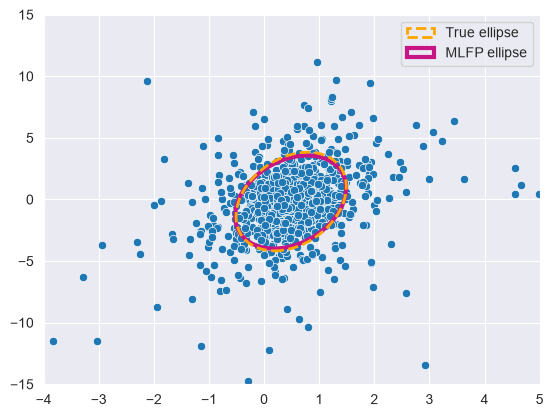

In [17]:
# parameters for ellipses based on covariance and radius (width, height, angle)
ellipse_params = lambda sigma2, r: (2*r*sqrt(eig(sigma2)[0][0]), 2*r*sqrt(eig(sigma2)[0][1]),
                                    degrees(atan(eig(sigma2)[1][1, 0]/eig(sigma2)[1][1, 1])))
# true ellipse
width, height, angle = ellipse_params(sigma2 , 2)
true_ellipse = Ellipse(mu, width, height, angle=angle , fill=False, lw=2, color='orange',
                       linestyle='--', label='True ellipse', zorder=3)

# MLFP ellipse
width, height, angle = ellipse_params(sigma2_mlfp, 2)
mlfp_ellipse = Ellipse(mu_mlfp, width, height, angle=angle, fill=False,
                      lw=3, color='#c71585', label='MLFP ellipse', zorder=2)

################################# plot #################################
# scatter plot with overimposed ellipsoids
scatterplot(x=eps[:, 0], y=eps[:, 1])
gca().add_patch(true_ellipse); gca().add_patch(mlfp_ellipse); legend();

## zooming in after the plot because outlier is causing everything to squash into a small area
from matplotlib.pyplot import xlim, ylim
xlim(-4, 5); ylim(-15, 15)

On fat tailed data,  the sample covariance is both biased and unstable.

Maximum likelihood with flexible probabilities fixes this by down-weighting outliers and old data,
and simulation is how I prove that it works.

In an interview, that's the sentence I should use and then
I should then unpack the details that back this up.

In practice, I would rarely say that i'll use MLFP, but I may say I need a robust,
time weighted covariance estimate for fat tailed returns and MLFP is 1 principled way to get it.

When it would be used...

1. Covariance inputs for portfolio construction
2. Risk models: VaR, expected shortfall, scenario generation (ARPM's main used case)
3. Regime-aware and stress estimates
4. Hedge ratios and pairs trading
5. Anomaly detection

When it would not be used:

1. Too many assets relative to data
2. Near-normal data with lots of history.
3. When the tails are the point.

An interview angle..

If I set the v -> infinity (symbol) the outlier weights all become 1, and MLFP with
exponential decay probabilities reduces exactly to the EWMA covariance used in Risk metrics,
one of the most widely used risk models in industry.
So I could describe EWMA with automatic outlier down weighting, justified by a Student t model.
This shows that I understand the industry standard and how to improve it.